# Filament Finder: clean the data and predict peak stress

Run cells from top to bottom, like the class notebook. Use Jupyter locally, or upload
the notebook and the three raw CSV files to Colab. No API key is needed here.

**Goal:** use pandas to clean three sources, remove open-printer experiments, compare
a random forest with a material-average baseline, and export ML-enhanced data for the app.
The ML task predicts specimen peak stress, not the load capacity of a finished object.


In [1]:
from pathlib import Path  # Make file locations easy to follow.
import json  # Save reproducible model settings and results.
import pandas as pd  # Read, clean, and export tables.
import matplotlib.pyplot as plt  # Draw evaluation charts.
from IPython.display import display  # Display notebook tables.

DATA = Path("data")  # Run this notebook from the project folder.
if not (DATA / "performance_raw.csv").exists():
    DATA = Path(".")  # Colab option: upload the renamed raw CSV files beside this notebook.
assert (DATA / "performance_raw.csv").exists(), "Upload the raw CSV files first; see README.md."
plt.rcParams["figure.figsize"] = (8, 4)


## 1. Import the original datasets


In [2]:
performance = pd.read_csv(DATA / "performance_raw.csv")
descriptions = pd.read_csv(DATA / "descriptions_raw.csv")
reviews = pd.read_csv(DATA / "reviews_raw.csv")
display(pd.DataFrame({"Dataset": ["Performance", "Descriptions", "Reviews"],
                      "Rows": [len(performance), len(descriptions), len(reviews)]}))
display(performance.head())
display(descriptions.head())
display(reviews.head())


,Dataset,Rows
0,Performance,500
1,Descriptions,8
2,Reviews,707


,Sample No,Printer Type,Material,Layer Thickness (mm),Infill Density (%),Infill Pattern,Speed (mm/s),Roughness AVG,Hardness AVG,Peak Load (N),Peak Stress (kPa),Strain at Break (mm/mm),Modulus (MPa),Width (mm),Thickness (mm),Unnamed: 15,Unnamed: 16,Unnamed: 17
0,1,closed,PLA+,0.1,20,Grid,30,2.579000,54.3,518.848000,24755.06667,0.013667,2128.810667,6.116667,3.426667,NaN,NaN,NaN
1,2,closed,PLA+,0.1,20,Grid,50,2.836333,60.9,477.144333,22743.13333,0.013000,2068.996000,6.063333,3.460000,NaN,NaN,452.0
2,3,closed,PLA+,0.1,20,Grid,70,3.271667,62.4,481.243000,21676.16667,0.012333,2009.842333,6.383333,3.480000,NaN,NaN,NaN
3,4,closed,PLA+,0.1,20,Triangles,30,2.570333,61.5,465.988667,21275.93333,0.012000,2065.603000,6.246667,3.506667,NaN,NaN,NaN
4,5,closed,PLA+,0.1,20,Triangles,50,2.717667,63.8,475.511000,22436.36667,0.012333,2050.737667,6.173333,3.433333,NaN,47.0,NaN


,Material,Description
0,PLA,Polylactic Acid (PLA) filament is a biodegrada...
1,ABS,Acrylonitrile butadiene styrene (ABS) filament...
2,PETG,Polyethylene terephthalate glycol-modified (PE...
3,TPU,Thermoplastic polyurethane (TPU) filament is a...
4,PLA-CF,Carbon fiber filament is a composite material ...


,rating_out_of_5,reviewer_name,product,material_type,review
0,5,Jason Lourigan,SUNLU PLA filament — Color: Black; Size: 4 kg,PLA,My New Go-To Black PLA\n\nThis black PLA has p...
1,5,Ernesto Rodriguez Rodriguez,SUNLU PLA filament — Color: Black; Size: 1 kg,PLA,Outstanding print quality and zero headaches o...
2,5,Lisa,SUNLU PLA filament — Color: Black; Size: 1 kg,PLA,Good quality filament\n\nI love this brand of ...
3,5,Jarrod,SUNLU PLA filament — Color: Black; Size: 4 kg,PLA,Great Filament!!!\n\nI was looking for a less ...
4,4,Craig E. Belcher,SUNLU PLA filament — Color: Black; Size: 1 kg,PLA,"Great filament for prototyping, save the expen..."


## 2. Clean labels and keep only closed printers

Normalize spaces/case before filtering so `Open` and `open` behave identically.
Remove the unnamed spreadsheet columns (two contain isolated stray numbers).
Keep original raw files unchanged. Source IDs allow the app to point back to rows.


In [3]:
original_count = len(performance)
performance = performance.loc[:, ~performance.columns.str.startswith("Unnamed")].copy()
performance["Printer Type"] = performance["Printer Type"].str.strip().str.lower()
printer_counts = performance["Printer Type"].value_counts().rename("Rows before filtering")
performance = performance[performance["Printer Type"] == "closed"].copy()
performance["Infill Pattern"] = (performance["Infill Pattern"].str.strip().str.lower()
                                  .replace({"zig zag": "zigzag"}))
performance["source_id"] = performance["Sample No"].map(lambda x: f"EXP-{int(x):03d}")
descriptions["source_id"] = [f"DESC-{i+1:03d}" for i in range(len(descriptions))]
reviews["source_id"] = [f"REV-{i+1:03d}" for i in range(len(reviews))]

display(printer_counts.to_frame())
print(f"Removed {original_count - len(performance)} non-closed rows; kept {len(performance)} closed-printer rows.")


,Rows before filtering
Printer Type,
closed,453
open,47


Removed 47 non-closed rows; kept 453 closed-printer rows.


## 3. Match material names without merging different polymers

The supplied `PLA phosphor` description explicitly says glow-in-the-dark filament.
We map that name, `PLA phosphorus`, and review label `PLA Phosphorus` to
`PLA-GLOW` as a documented working assumption. Confirm this with the experimental
source before final submission. PETG-CF, PETG-GF, PAHT-CF and PLA-CF stay distinct.
Preserve product names and brands in reviews. Descriptions are supplied text, not
verified specifications; collection URLs and source metadata still need documenting.


In [4]:
material_names = {"pla": "PLA", "pla+": "PLA+", "abs": "ABS", "petg": "PETG",
                  "tpu": "TPU", "pp": "PP", "pla-cf": "PLA-CF", "rpet": "rPET",
                  "pla-transparent": "PLA-transparent", "pla phosphorus": "PLA-GLOW",
                  "pla phosphor": "PLA-GLOW", "petg-cf": "PETG-CF",
                  "petg-gf": "PETG-GF", "paht-cf": "PAHT-CF", "pc": "PC"}
reviews = reviews.rename(columns={"material_type": "Material"})
for table in [performance, descriptions, reviews]:
    table["Material_original"] = table["Material"]
    table["Material"] = table["Material"].str.strip().str.lower().map(material_names)

descriptions["Description"] = descriptions["Description"].str.strip()
descriptions = descriptions.dropna(subset=["Material", "Description"])
descriptions = descriptions[descriptions.Description.ne("")].drop_duplicates(["Material", "Description"])
reviews["review"] = reviews["review"].str.replace(r"\n", "\n", regex=False).str.strip()
reviews["rating_out_of_5"] = pd.to_numeric(reviews["rating_out_of_5"], errors="coerce")
reviews = reviews.dropna(subset=["Material", "review", "rating_out_of_5"])
reviews = reviews[reviews.rating_out_of_5.between(1, 5) & reviews.review.ne("")]
reviews = reviews.drop_duplicates(["Material", "product", "review"])

coverage = pd.concat([performance.Material.value_counts().rename("Experiments"),
                      descriptions.Material.value_counts().rename("Descriptions"),
                      reviews.Material.value_counts().rename("Reviews")], axis=1).fillna(0).astype(int)
display(coverage)
print("App materials:", sorted(set(performance.Material) & set(descriptions.Material)))


,Experiments,Descriptions,Reviews
Material,,,
PLA+,213,1,100
PETG,81,1,99
PLA-CF,27,1,8
PLA-GLOW,27,1,100
TPU,27,1,100
ABS,27,1,100
PLA-transparent,24,0,0
PLA,9,1,100
PP,9,1,7


App materials: ['ABS', 'PETG', 'PLA', 'PLA+', 'PLA-CF', 'PLA-GLOW', 'PP', 'TPU']


## 4. Choose inputs and target

Use properties known BEFORE printing. Do not include peak load, measured modulus,
roughness, specimen dimensions, or sample IDs as predictors. Printer type is constant
after filtering, so it is excluded. Convert kPa to MPa by dividing by 1,000.
Missing strain-at-break values can remain: that column is not used by this model.


In [5]:
categorical = ["Material", "Infill Pattern"]
numeric = ["Layer Thickness (mm)", "Infill Density (%)", "Speed (mm/s)"]
features = categorical + numeric
for column in numeric + ["Peak Stress (kPa)"]:
    performance[column] = pd.to_numeric(performance[column], errors="coerce")
performance["Peak Stress (MPa)"] = performance["Peak Stress (kPa)"] / 1000
before = len(performance)
performance = performance.dropna(subset=features + ["Peak Stress (MPa)"])
performance = performance[performance["Peak Stress (MPa)"] > 0].copy()
print("Additional unusable modeling rows removed:", before - len(performance))
display(performance[features + ["Peak Stress (MPa)"]].head())
display(performance.isna().sum().rename("Missing cells").to_frame())
assert performance["Printer Type"].eq("closed").all()
assert not performance.duplicated(features).any(), "Group repeated configurations before splitting."


,Material,Infill Pattern,Layer Thickness (mm),Infill Density (%),Speed (mm/s),Peak Stress (MPa)
0,PLA+,grid,0.1,20,30,24.755067
1,PLA+,grid,0.1,20,50,22.743133
2,PLA+,grid,0.1,20,70,21.676167
3,PLA+,triangles,0.1,20,30,21.275933
4,PLA+,triangles,0.1,20,50,22.436367


,Missing cells
Sample No,0
Printer Type,0
Material,0
Layer Thickness (mm),0
Infill Density (%),0
Infill Pattern,0
Speed (mm/s),0
Roughness AVG,0
Hardness AVG,0
Peak Load (N),0


Additional unusable modeling rows removed: 0


## 5. Hold out experiments and train a forest

Reserve 20% for testing, stratifying by material so every material is represented.
No input configuration repeats in this cleaned file (checked above). This is a row
holdout, not proof of generalization to new printers, brands, materials, or lab batches;
the source provides no batch IDs. The test set is not used to fit preprocessing.
One-hot encoding gives text categories numeric indicator columns. Scaling is not
needed for the tree model. Keep these settings fixed rather than tuning on test data.


In [6]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

train, test = train_test_split(performance, test_size=0.2, random_state=42,
                               stratify=performance["Material"])
preprocessing = ColumnTransformer([("categories", OneHotEncoder(handle_unknown="ignore"), categorical),
                                   ("numbers", "passthrough", numeric)])
forest = Pipeline([("prepare", preprocessing),
                   ("model", RandomForestRegressor(n_estimators=200, min_samples_leaf=3,
                                                    max_features=1.0, random_state=42))])
forest.fit(train[features], train["Peak Stress (MPa)"])
forest_predictions = forest.predict(test[features])
material_means = train.groupby("Material")["Peak Stress (MPa)"].mean()
baseline_predictions = test["Material"].map(material_means)
print(f"Training rows: {len(train)}; held-out test rows: {len(test)}")


Training rows: 362; held-out test rows: 91


## 6. Compare against the baseline

MAE is the average absolute prediction error in MPa; lower is better. Inspect errors
by material because PLA+ contributes many more rows than PP or PLA. Small per-material
test sets give uncertain error estimates. This evaluates ML, not the separate LLM benchmark.


,Method,MAE_MPa
0,Material mean,4.366
1,Random forest,2.858


,test_rows,forest_MAE_MPa,baseline_MAE_MPa
Material,,,
ABS,5,2.797,1.251
PETG,16,1.247,2.055
PLA,2,6.215,1.722
PLA+,43,2.753,5.600
PLA-CF,5,2.309,3.354
PLA-GLOW,6,2.646,5.039
PLA-transparent,5,4.581,6.426
PP,2,3.341,0.184
TPU,5,3.793,5.818


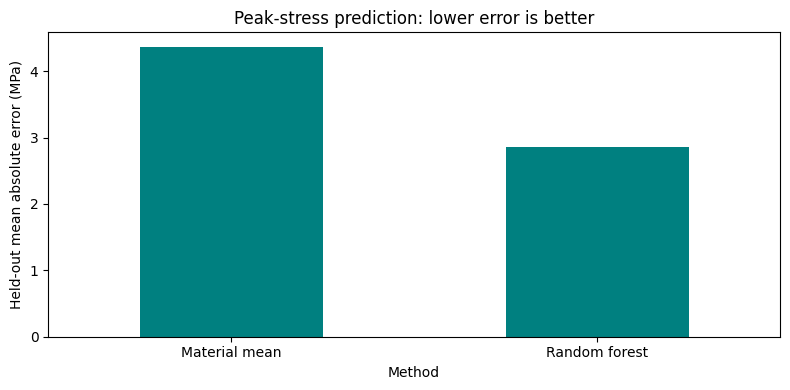

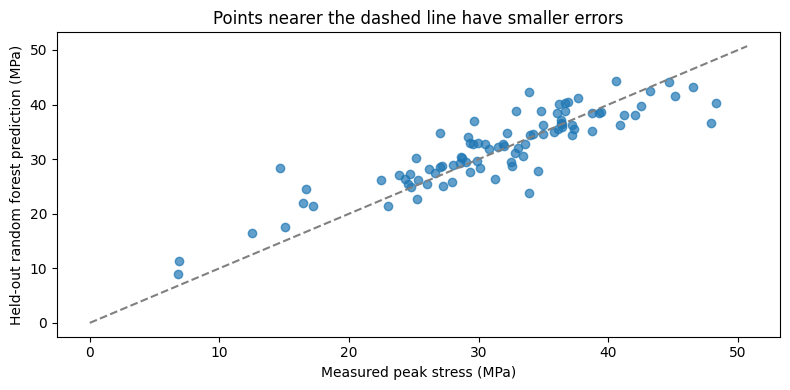

In [7]:
scores = pd.DataFrame({"Method": ["Material mean", "Random forest"],
                        "MAE_MPa": [mean_absolute_error(test["Peak Stress (MPa)"], baseline_predictions),
                                    mean_absolute_error(test["Peak Stress (MPa)"], forest_predictions)]})
display(scores.round(3))
held_out = test[["source_id", "Material", "Peak Stress (MPa)"]].copy()
held_out["forest_prediction_MPa"] = forest_predictions
held_out["baseline_prediction_MPa"] = baseline_predictions.to_numpy()
held_out["forest_absolute_error_MPa"] = abs(held_out["Peak Stress (MPa)"] - forest_predictions)
held_out["baseline_absolute_error_MPa"] = abs(held_out["Peak Stress (MPa)"] - baseline_predictions)
display(held_out.groupby("Material").agg(test_rows=("source_id", "size"),
          forest_MAE_MPa=("forest_absolute_error_MPa", "mean"),
          baseline_MAE_MPa=("baseline_absolute_error_MPa", "mean")).round(3))
scores.plot.bar(x="Method", y="MAE_MPa", legend=False, rot=0, color="teal")
plt.ylabel("Held-out mean absolute error (MPa)")
plt.title("Peak-stress prediction: lower error is better")
plt.tight_layout()
plt.savefig(DATA / "ml_error_comparison.png", dpi=150)
plt.show()
plt.scatter(held_out["Peak Stress (MPa)"], held_out.forest_prediction_MPa, alpha=0.7)
limits = [0, max(held_out["Peak Stress (MPa)"].max(), held_out.forest_prediction_MPa.max()) * 1.05]
plt.plot(limits, limits, color="gray", linestyle="--")
plt.xlabel("Measured peak stress (MPa)")
plt.ylabel("Held-out random forest prediction (MPa)")
plt.title("Points nearer the dashed line have smaller errors")
plt.tight_layout()
plt.savefig(DATA / "ml_predictions.png", dpi=150)
plt.show()


## 7. Add model estimates and export the prepared tables

Use the method with lower held-out MAE, then refit using all usable rows. The new
column contains fitted/smoothed estimates for observed configurations. These are NOT
new experiments, independent test predictions, or estimates of unobserved combinations.
Use `ml_held_out_predictions.csv` for honest evaluation instead. The app looks up the
nearest observed settings and exposes any mismatch instead of inventing full coverage.
All 10 experimental materials remain in the table; the app initially recommends only
the 8 that also have descriptions. Review-only polymers are preserved but not recommended.


In [8]:
selected_method = scores.sort_values("MAE_MPa").iloc[0]["Method"]
if selected_method == "Random forest":
    forest.fit(performance[features], performance["Peak Stress (MPa)"])
    performance["predicted_peak_stress_MPa"] = forest.predict(performance[features])
else:
    final_means = performance.groupby("Material")["Peak Stress (MPa)"].mean()
    performance["predicted_peak_stress_MPa"] = performance.Material.map(final_means)
performance["prediction_method"] = selected_method
performance["prediction_scope"] = "Fitted estimate at an observed closed-printer configuration"
performance.to_csv(DATA / "performance_prepared.csv", index=False)
descriptions.to_csv(DATA / "descriptions_clean.csv", index=False)
reviews.to_csv(DATA / "reviews_clean.csv", index=False)
held_out.to_csv(DATA / "ml_held_out_predictions.csv", index=False)
scores.to_csv(DATA / "ml_metrics.csv", index=False)
coverage.to_csv(DATA / "material_coverage.csv")
metadata = {"random_state": 42, "test_fraction": 0.2, "features": features,
            "target": "Peak Stress (MPa)", "selected_method": selected_method,
            "forest_parameters": {"n_estimators": 200, "min_samples_leaf": 3, "max_features": 1.0},
            "source_files": ["performance_raw.csv", "descriptions_raw.csv", "reviews_raw.csv"],
            "training_source_rows": len(performance), "held_out_rows": len(test),
            "scores": scores.to_dict("records"),
            "limitations": ["Closed printers only", "Uneven material coverage", "No batch IDs",
                "Final predictions are fitted estimates", "PLA-GLOW alias needs source confirmation",
                "Source URLs, test protocol, and brand transfer need documentation"]}
(DATA / "ml_metadata.json").write_text(json.dumps(metadata, indent=2))
print("Exported prepared data. Selected method:", selected_method)
display(performance[["source_id", "Material", "Peak Stress (MPa)", "predicted_peak_stress_MPa"]].head(10).round(3))


,source_id,Material,Peak Stress (MPa),predicted_peak_stress_MPa
0,EXP-001,PLA+,24.755,24.161
1,EXP-002,PLA+,22.743,24.272
2,EXP-003,PLA+,21.676,24.383
3,EXP-004,PLA+,21.276,23.719
4,EXP-005,PLA+,22.436,23.710
5,EXP-006,PLA+,21.910,23.786
6,EXP-007,PLA+,23.589,25.693
7,EXP-008,PLA+,22.762,25.333
8,EXP-009,PLA+,22.296,25.256
9,EXP-010,PLA+,22.987,25.043


Exported prepared data. Selected method: Random forest


## Next: launch the app

The notebook is the full cleaning/training record. No separate training file or model
server is needed. The app reads the prepared CSVs, uses smolagents tools to compare
estimates and retrieve source excerpts, then checks the recommendation structure.
See README.md for installation, API configuration, and the separate agent benchmark.
